# Burgers: comparación controlada PINN base vs PCA con autodiferenciación

Este notebook presenta la corrida de 10 semillas guardada en `results/burgers/base_vs_pca/controlled_ad_10_seeds_v1/`. El foco es comprobar si PCA acelera el entrenamiento cuando ambos modelos optimizan el residuo de Burgers con autodiferenciación de JAX.


## Protocolo empírico

- Se usa el mismo conjunto de datos y, dentro de cada semilla, las mismas particiones temporales, minibatches supervisados, coordenadas de colocación y puntos de condición inicial.
- PCA se ajusta solo con perfiles espaciales de tiempos de entrenamiento. `k` es el menor número de componentes que conserva al menos 99% de la varianza.
- Las redes se emparejan por cantidad de parámetros (diferencia menor a 5%).
- En ambas variantes, JAX autodiferencia la solución para calcular `u_t`, `u_x` y `u_xx`. Para PCA, la reconstrucción espacial usa interpolación cúbica de Hermite diferenciable.
- El tiempo de compilación se mide aparte. Se incluye la evaluación de validación periódica en ambos tiempos de entrenamiento; el tiempo del pipeline PCA incluye además el ajuste de la base.
- Los objetivos de validación (RMSE ≤ 0.30, 0.25 y 0.20) se fijaron en la configuración antes de correr. El residuo físico de prueba se calcula con el mismo operador discreto sobre la malla para ambos modelos.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
RUN_DIR = ROOT / "results" / "burgers" / "base_vs_pca" / "controlled_ad_10_seeds_v1"
CONFIG = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))
METRICS = pd.read_csv(RUN_DIR / "metrics.csv")
TRAJECTORIES = pd.read_csv(RUN_DIR / "validation_trajectories.csv")
print(f"JAX {RESULT['runtime']['jax']} | {RESULT['runtime']['device']}")
print(f"Semillas: {len(CONFIG['seeds'])} | pasos: {CONFIG['steps']} | umbral de varianza PCA: {CONFIG['pca_variance_threshold']:.0%}")


JAX 0.12.0.1 | cpu:0
Semillas: 10 | pasos: 1000 | umbral de varianza PCA: 99%


## Métricas finales por modelo


In [2]:
summary = RESULT["summary"]
rows = []
for name, stats in summary.items():
    rows.append({
        "Modelo": name,
        "Semillas": stats["seed_count"],
        "k promedio": None if stats["k"] is None else stats["k"]["mean"],
        "Varianza retenida": None if stats["retained_variance"] is None else stats["retained_variance"]["mean"],
        "Parámetros": stats["parameters_mean"],
        "RMSE prueba": f"{stats['test_rmse']['mean']:.4f} ± {stats['test_rmse']['std']:.4f}",
        "Error relativo L2": f"{stats['test_relative_l2']['mean']:.4f} ± {stats['test_relative_l2']['std']:.4f}",
        "Residuo Burgers RMS": f"{stats['test_pde_residual_rms']['mean']:.4f} ± {stats['test_pde_residual_rms']['std']:.4f}",
        "Pipeline": f"{stats['pipeline_seconds']['mean']:.3f} ± {stats['pipeline_seconds']['std']:.3f} s",
    })
display(pd.DataFrame(rows))


Modelo,Semillas,k promedio,Varianza retenida,Parámetros,RMSE prueba,Error relativo L2,Residuo Burgers RMS,Pipeline
PINN base,10,—,—,8577,0.2446 ± 0.0187,0.3986 ± 0.0217,0.2511 ± 0.0203,2.239 ± 0.080 s
PCA AD,10,3.0,99.755%,8643,0.1854 ± 0.0090,0.3023 ± 0.0099,0.3459 ± 0.0175,1.335 ± 0.043 s


## Tiempo hasta el umbral de validación


In [3]:
target_rows = []
for name, stats in RESULT["summary"].items():
    for target, values in stats["time_to_target"].items():
        target_rows.append({
            "Modelo": name,
            "Umbral": target.replace("val_rmse_", "RMSE ≤ "),
            "Semillas que lo alcanzaron": f"{values['hit_count']}/{values['seed_count']}",
            "Tiempo promedio entre las que lo alcanzaron": values["seconds_mean_if_hit"],
        })
display(pd.DataFrame(target_rows))


Modelo,Umbral,Semillas que lo alcanzaron,Tiempo promedio entre las que lo alcanzaron
PINN base,RMSE ≤ 0_3,10/10,0.877 s
PINN base,RMSE ≤ 0_25,5/10,1.538 s
PINN base,RMSE ≤ 0_2,0/10,—
PCA AD,RMSE ≤ 0_3,10/10,0.071 s
PCA AD,RMSE ≤ 0_25,10/10,0.071 s
PCA AD,RMSE ≤ 0_2,7/10,0.172 s


## Resultados y convergencia


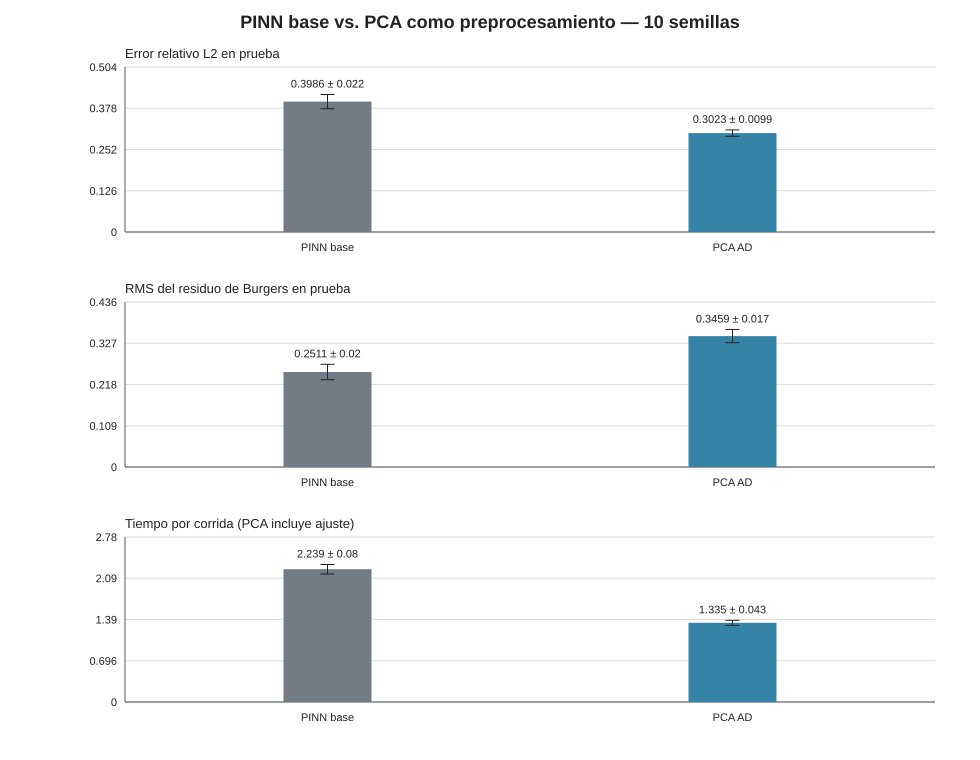

In [4]:
display(SVG(filename=str(RUN_DIR / "summary.svg")))


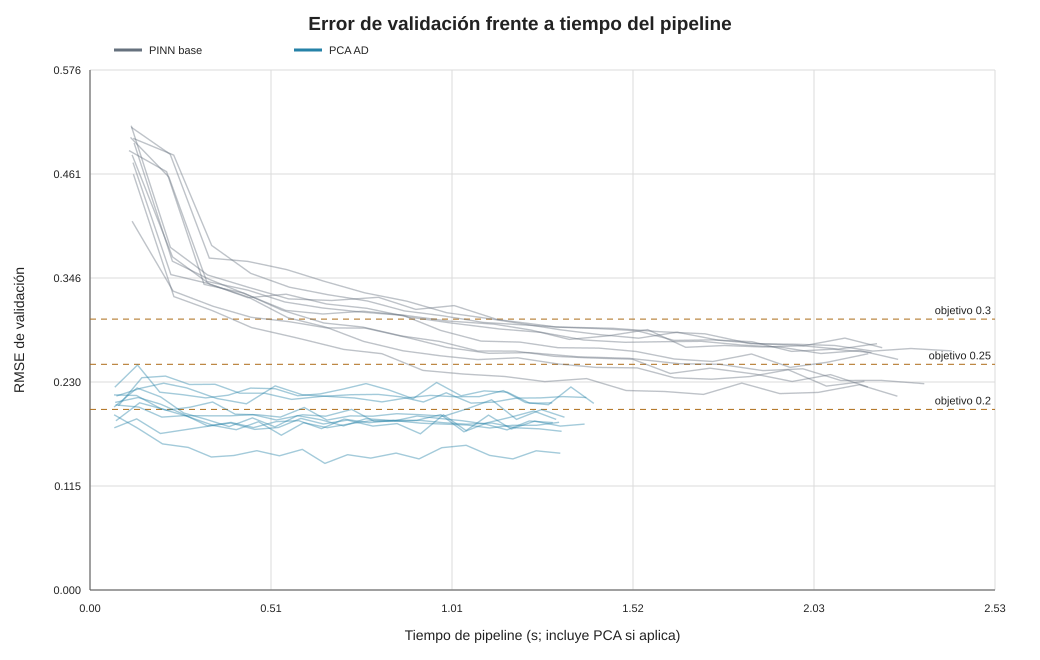

In [5]:
display(SVG(filename=str(RUN_DIR / "validation_vs_time.svg")))


## Lectura de esta corrida

PCA reduce el tiempo de pipeline y el error de solución en esta configuración. A la vez, su residuo físico de prueba es mayor que el de la PINN base. La compresión de la solución a pocos modos puede facilitar el ajuste de los datos y restringir las funciones disponibles para satisfacer la ecuación; por eso no basta con comparar RMSE o tiempo. Estas cifras describen este benchmark de Burgers, no una conclusión general sobre otras ecuaciones o configuraciones.


## Reproducir la corrida

La corrida usada para producir los resultados se ejecutó con `scripts/run_controlled_experiment.py` y `configs/burgers_controlled_ad.json`. La siguiente celda está desactivada para que abrir el notebook no vuelva a entrenar automáticamente.


In [ ]:
# Descomenta las últimas dos líneas para volver a ejecutar las 10 semillas.
# from pinn_pca.controlled import run_controlled_comparison
# regenerated = run_controlled_comparison(CONFIG, ROOT)
